In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import torch 
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from tools.draw import draw_score
from sklearn.datasets import make_moons

torch.Size([1000, 2])


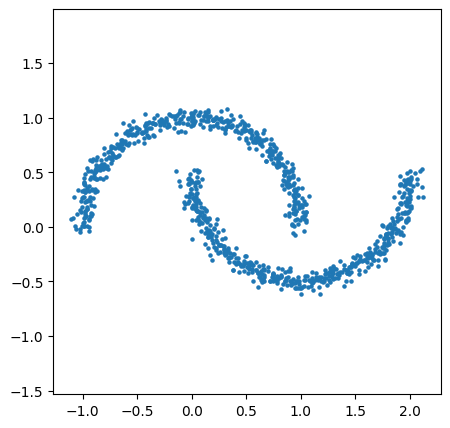

In [2]:
x, _ = make_moons(
    n_samples=1000,
    noise=0.05,
    random_state=42
)

x0 = torch.tensor(x, dtype=torch.float32)
print(x0.shape)

plt.figure(figsize=(5, 5))
plt.scatter(x0[:, 0], x0[:, 1], s=5)
plt.axis("equal")
plt.show()

# DSM

In [ ]:
sigma = 0.2
def q_sample(x0, sigma, device="cpu"):
    x0 = x0.to(device)
    noise = torch.randn_like(x0)
    x_tilde = x0 + sigma*noise

    return x_tilde, noise

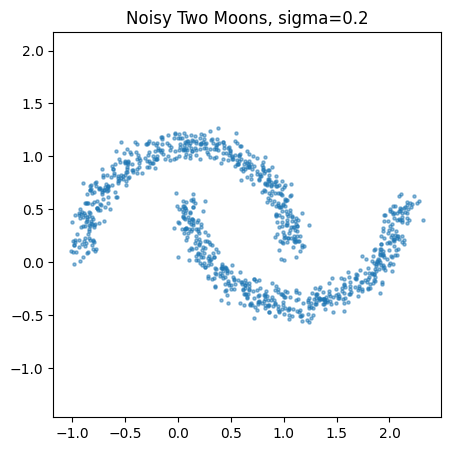

In [4]:
x_tilde, noise = q_sample(x0, sigma)

plt.figure(figsize=(5, 5))
plt.scatter(
    x_tilde[:, 0].cpu(),
    x_tilde[:, 1].cpu(),
    s=5,
    alpha=0.5
)
plt.axis("equal")
plt.title(f"Noisy Two Moons, sigma={sigma}")
plt.show()

In [5]:
class ScoreNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(2, 256)
        self.fc2 = nn.Linear(256,128)
        self.fc3 = nn.Linear(128,2)

    def forward(self, x):
        x = F.silu(self.fc1(x))
        x = F.silu(self.fc2(x))
        return self.fc3(x)

In [ ]:
def DSM_train(model, x0, sigma, epochs, B, device):
    history=[]
    for epoch in range(epochs):
        model.train()
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        indices = torch.randperm(len(x0), device=device)

        epoch_loss = 0.0
        for start in range(0, len(x0), B):  #run every sample in epoch
            idx = indices[start:start+B]

            x0_batch = x0[idx]
            noise = torch.randn_like(x0_batch)
            x_tilde = x0_batch + sigma*noise

            target = -noise / sigma
            pred = model(x_tilde)

            loss = F.mse_loss(pred, target)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()*len(x0_batch)

        epoch_loss /= len(x0)
        history.append(epoch_loss)
        if (epoch+1)%100 == 0:
            print(f"Epoch: {epoch+1}/{epochs}, Epoch_loss: {epoch_loss:.4f}")
    return history




device = "cuda" if torch.cuda.is_available() else "cpu"
model = ScoreNet().to(device)
x0 = x0.to(device)
epoch = 1000
B = 256
sigma = 0.05

DSM_train(model, x0, sigma, epoch, B, device)
print(print("model device =", next(model.parameters()).device))


Epoch: 100/1000, Epoch_loss: 404.4076
Epoch: 200/1000, Epoch_loss: 352.3472
Epoch: 300/1000, Epoch_loss: 345.4017
Epoch: 400/1000, Epoch_loss: 329.1268
Epoch: 500/1000, Epoch_loss: 317.7849
Epoch: 600/1000, Epoch_loss: 327.1152
Epoch: 700/1000, Epoch_loss: 299.5632
Epoch: 800/1000, Epoch_loss: 312.3160
Epoch: 900/1000, Epoch_loss: 308.0009
Epoch: 1000/1000, Epoch_loss: 297.5228
model device = cuda:0
None


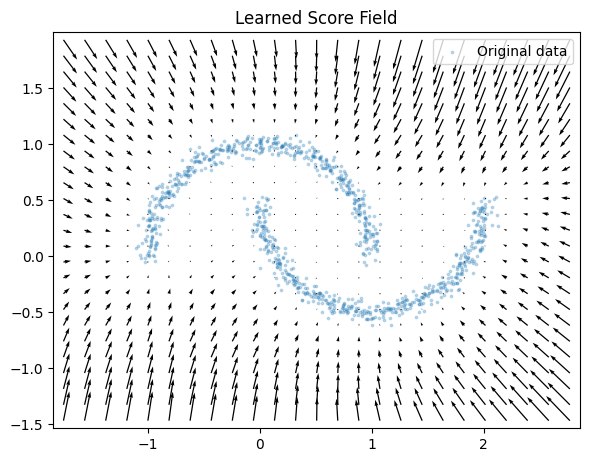

In [7]:
draw_score.score_field(model, x0);


In [ ]:
@torch.no_grad()
def DSM_inference(model, N, steps, eta, device):
    model.eval()
    x = torch.randn(N, 2, device=device)
    model = model.to(device)

    save_steps = [0, 50, 200, 500, 1000]
    history = {0: x.detach().cpu().clone()}
    for step in range(1, steps+1):
        score = model(x)
        noise = torch.randn_like(x)
        x += eta*score + (2*eta)**0.5*noise
        if step in save_steps:
            history[step] = x.detach().cpu().clone()
    return x, history

samples, history = DSM_inference(
    model=model,
    N=2000,
    steps=1000,
    eta=1e-4,
    device=device
)

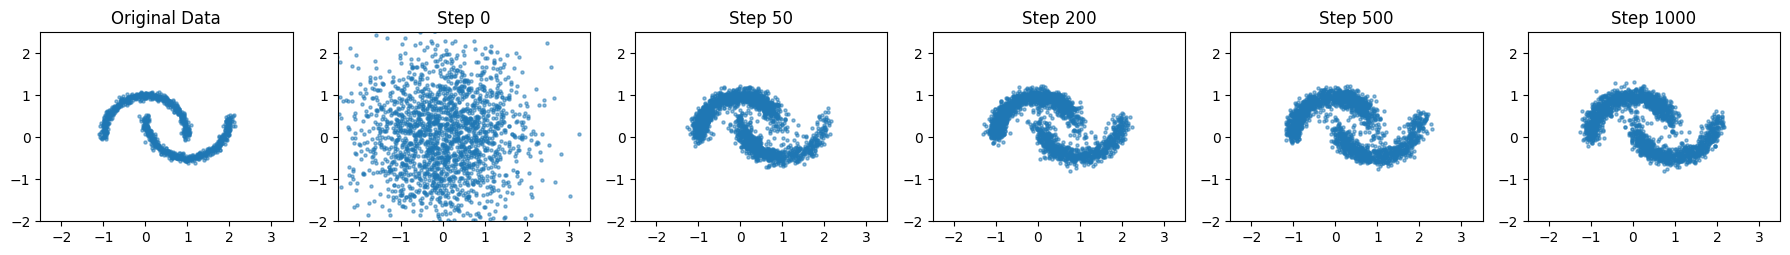

In [9]:
def plot_DSM_inference(history, x0):
    save_steps = sorted(history.keys())

    fig, axes = plt.subplots(1, len(save_steps) + 1, figsize=(18, 3.5))

    # Original data
    original = x0.detach().cpu().numpy()

    axes[0].scatter(
        original[:, 0], original[:, 1],
        s=5, alpha=0.5
    )
    axes[0].set_title("Original Data")

    # Langevin sampling
    for i, step in enumerate(save_steps):
        samples = history[step].numpy()

        axes[i + 1].scatter(
            samples[:, 0],
            samples[:, 1],
            s=5,
            alpha=0.5
        )

        axes[i + 1].set_title(f"Step {step}")

    for ax in axes:
        ax.set_xlim(-2.5, 3.5)
        ax.set_ylim(-2, 2.5)
        ax.set_aspect("equal")

    plt.tight_layout()
    plt.show()

plot_DSM_inference(history, x0)

# NCSN

In [10]:
class NCSN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(3,256)
        self.fc2 = nn.Linear(256,128)
        self.fc3 = nn.Linear(128,2)

    def forward(self, x, sigma):
        B = x.shape[0]
        sigma = torch.as_tensor(sigma, device=x.device, dtype=x.dtype).reshape(-1,1)
        if sigma.shape[0] == 1:
            sigma = sigma.expand(B, 1)

        h = torch.cat([x,sigma],dim=1)

        h = F.silu(self.fc1(h))
        h = F.silu(self.fc2(h))

        score = self.fc3(h)
        return score

In [11]:
def NCSN_train(model, x0, sig_min, sig_max, L, B, epochs, device):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    x0 = x0.to(device)

    sigmas=[]
    for i in range(L):
        sigma_i = sig_max*(sig_min/sig_max)**(i/(L-1))
        sigmas.append(sigma_i)
    sigmas = torch.tensor(sigmas, device=device, dtype=x0.dtype)

    history=[]
    for epoch in range(epochs):
        model.train()
        idx = torch.randperm(len(x0), device=device)

        epoch_loss = 0.0
        for start in range(0, len(x0), B):
            batch_idx = idx[start : start+B]
            x0_batch = x0[batch_idx]
            noise = torch.randn_like(x0_batch)

            batch_size = x0_batch.shape[0]
            sigma_idx = torch.randint(0,L,(batch_size,), device=device)
            sigma_batch = sigmas[sigma_idx].unsqueeze(1)

            x_tilde = x0_batch + sigma_batch*noise
            pred = model(x_tilde, sigma_batch)

            loss = F.mse_loss(-noise,sigma_batch*pred)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()*batch_size

        avg_loss = epoch_loss/len(x0)
        history.append(avg_loss)

        if (epoch + 1) % 500 == 0:
            print(f"Epoch {epoch+1}, Loss: {avg_loss:.4f}")

    return history

In [12]:
model = NCSN()
sig_min = 0.01
sig_max = 1.0
L = 10
B = 256
epochs = 2000
device = "cuda" if torch.cuda.is_available() else "cpu"

history = NCSN_train(model, x0, sig_min, sig_max, L, B, epochs, device)

Epoch 500, Loss: 0.8319
Epoch 1000, Loss: 0.7773
Epoch 1500, Loss: 0.7762
Epoch 2000, Loss: 0.8412


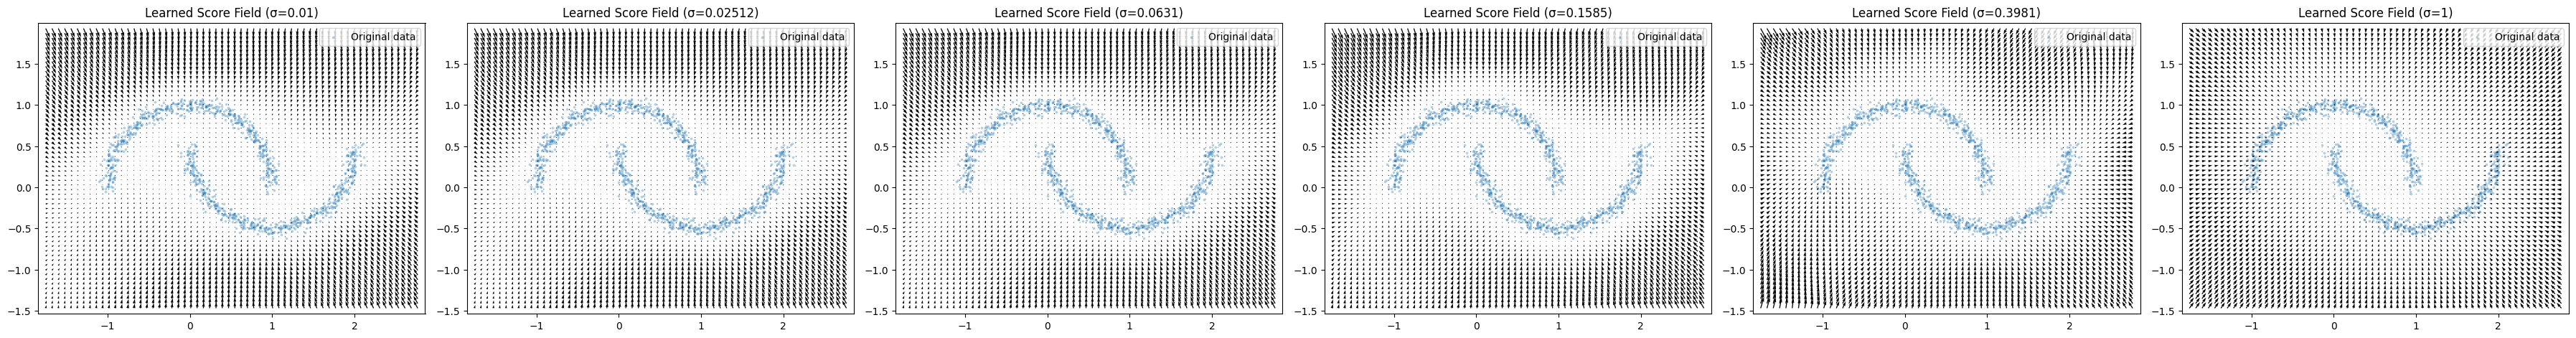

In [13]:
draw_score.score_field(model,x0,sigma=(0.01, 1.0),grid_size=60);

In [16]:
@torch.no_grad()
def NCSN_inference(model, N, L, sig_min, sig_max, device, eps=2e-5):
    model.eval()
    model = model.to(device)
    x = torch.randn((N,2), device=device, dtype=torch.float32)
    sigmas = np.geomspace(sig_max, sig_min, L)

    history = {"initial": x.cpu().clone()}
    for sigma in sigmas:
        alpha = (sigma**2/sig_min**2)* eps
        for _ in range(100):
            score = model(x, sigma)
            noise = torch.randn_like(x)
            x = x + alpha/2*score + np.sqrt(alpha)*noise
        history[float(sigma)] = x.cpu().clone()
    return x, history

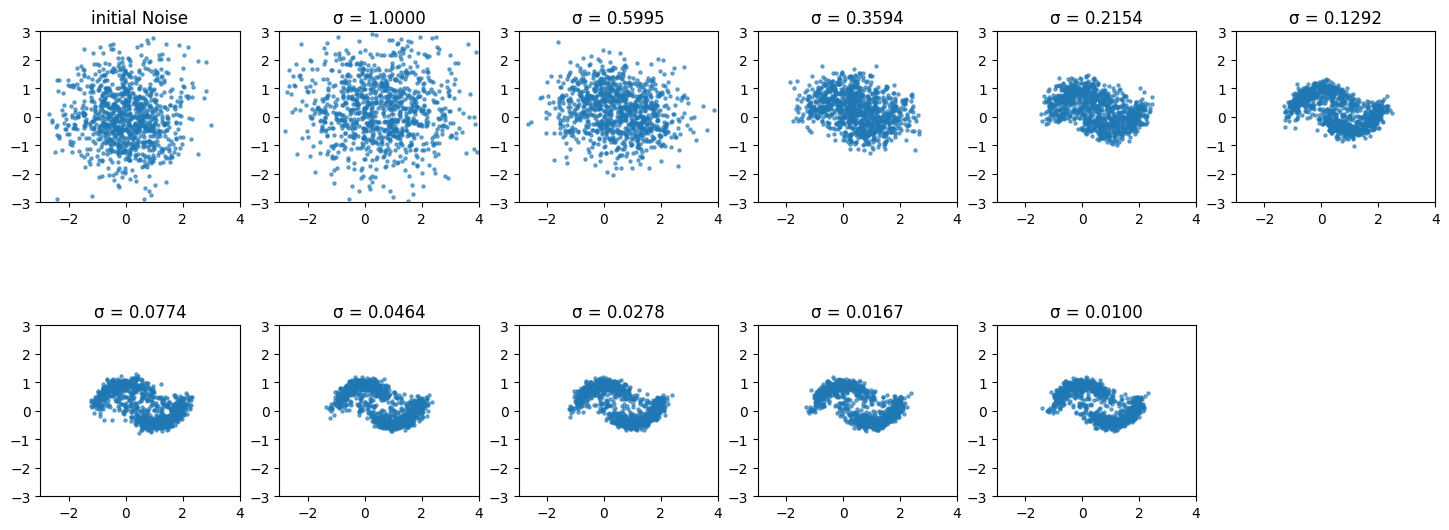

In [23]:
samples, history = NCSN_inference(
    model=model,
    N=1000,
    L=10,
    sig_min=0.01,
    sig_max=1.0,
    device=device
)
draw_score.NCSN_infer(history);